<a href="https://colab.research.google.com/github/Athenessa/bangkok-flood-data-analytics/blob/main/ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [188]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

# **Data prep for budget**

In [189]:
file = "/content/drive/MyDrive/study/Junior/Data_sci/Project/flooding_cleaned.xlsx"

In [190]:
df = pd.read_excel(file, sheet_name="budget")

bd = df.copy()
bd.head()

,district,level,district_en,impact_2011,impact_2026,events_2024-2025,events_over_3h,AVG_duration_time,flood_pattern,budget_total,budget_embarkment,embarkment_share,budget_drainage,drainage_share,budget_operating,budget_dredging,budget_retention,budget_pumps,budget_total_cal,budget_total_recheck
0,สำนักการระบายน้ำ,Central,not found,not found,not found,0,0,NaN,-,2245542017,0,0.000000,0,0.000000,2245542017,0,0,0,2245542017,True
1,ดอนเมือง,District,Don Mueang,high,medium,20,13,438.000000,ท่วมทั้ง 2 ปี,770908200,663106000,0.860162,67807000,0.087957,10674200,4521000,20000000,4800000,770908200,True
2,หลักสี่,District,Lak Si,high,high,52,4,82.365385,ท่วมทั้ง 2 ปี,694525825,497197725,0.715881,63871000,0.091963,21512100,4145000,99000000,8800000,694525825,True
3,คลองเตย,District,Khlong Toei,medium,none,36,2,82.222222,ท่วมปี 2011,662579448,459377715,0.693317,170303000,0.257030,8395400,24503333,0,0,662579448,True
4,หนองแขม,District,Nong Khaem,high,none,0,0,NaN,ท่วมปี 2011,658778795,514369262,0.780792,99955533,0.151729,10730500,23563500,0,10160000,658778795,True


In [191]:
bd.drop(columns = 'budget_total_recheck')

,district,level,district_en,impact_2011,impact_2026,events_2024-2025,events_over_3h,AVG_duration_time,flood_pattern,budget_total,budget_embarkment,embarkment_share,budget_drainage,drainage_share,budget_operating,budget_dredging,budget_retention,budget_pumps,budget_total_cal
0,สำนักการระบายน้ำ,Central,not found,not found,not found,0,0,NaN,-,2245542017,0,0.000000,0,0.000000,2245542017,0,0,0,2245542017
1,ดอนเมือง,District,Don Mueang,high,medium,20,13,438.000000,ท่วมทั้ง 2 ปี,770908200,663106000,0.860162,67807000,0.087957,10674200,4521000,20000000,4800000,770908200
2,หลักสี่,District,Lak Si,high,high,52,4,82.365385,ท่วมทั้ง 2 ปี,694525825,497197725,0.715881,63871000,0.091963,21512100,4145000,99000000,8800000,694525825
3,คลองเตย,District,Khlong Toei,medium,none,36,2,82.222222,ท่วมปี 2011,662579448,459377715,0.693317,170303000,0.257030,8395400,24503333,0,0,662579448
4,หนองแขม,District,Nong Khaem,high,none,0,0,NaN,ท่วมปี 2011,658778795,514369262,0.780792,99955533,0.151729,10730500,23563500,0,10160000,658778795
5,จตุจักร,District,Chatuchak,high,high,49,14,130.510204,ท่วมทั้ง 2 ปี,489673667,95000000,0.194007,341092667,0.696571,32425500,21155500,0,0,489673667
6,ยานนาวา,District,Yan Nawa,medium,none,3,0,60.000000,ท่วมปี 2011,383532460,305665960,0.796975,47995000,0.125139,7967500,21856000,0,48000,383532460
7,ดุสิต,District,Dusit,medium,medium,3,0,43.333333,ท่วมทั้ง 2 ปี,352362000,78790000,0.223605,204300000,0.579801,6783000,2398000,60000000,91000,352362000
8,บางแค,District,Bang Khae,high,none,18,3,111.888889,ท่วมปี 2011,336612031,178419818,0.530046,95003533,0.282235,15386680,43586000,0,4216000,336612031
9,บึงกุ่ม,District,Bueng Kum,medium,high,45,7,107.888889,ท่วมทั้ง 2 ปี,336442484,68600000,0.203898,165773424,0.492724,26340060,29633000,45300000,796000,336442484


In [192]:
bd.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51 entries, 0 to 50
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   district              51 non-null     object 
 1   level                 51 non-null     object 
 2   district_en           51 non-null     object 
 3   impact_2011           51 non-null     object 
 4   impact_2026           51 non-null     object 
 5   events_2024-2025      51 non-null     int64  
 6   events_over_3h        51 non-null     int64  
 7   AVG_duration_time     43 non-null     float64
 8   flood_pattern         51 non-null     object 
 9   budget_total          51 non-null     int64  
 10  budget_embarkment     51 non-null     int64  
 11  embarkment_share      51 non-null     float64
 12  budget_drainage       51 non-null     int64  
 13  drainage_share        51 non-null     float64
 14  budget_operating      51 non-null     int64  
 15  budget_dredging       51 

In [193]:
bd.isna().sum()

,0
district,0
level,0
district_en,0
impact_2011,0
impact_2026,0
events_2024-2025,0
events_over_3h,0
AVG_duration_time,8
flood_pattern,0
budget_total,0


## **Cat Data**

### **impact**

In [194]:
impact_mapping = {
    "none": 0,
    "medium": 1,
    "high": 2,
    #"not found": np.nan
}

In [195]:
bd = df.copy()

#Cleaning naka bc if not it's gonna get NaN (already try la)

bd['impact_2011'] = bd['impact_2011'].astype(str).str.strip().str.lower()
bd['impact_2026'] = bd['impact_2026'].astype(str).str.strip().str.lower()

bd['impact_2011'] = bd['impact_2011'].map(impact_mapping)
bd['impact_2026'] = bd['impact_2026'].map(impact_mapping)

bd[['impact_2011', 'impact_2026']]

,impact_2011,impact_2026
0,NaN,NaN
1,2.0,1.0
2,2.0,2.0
3,1.0,0.0
4,2.0,0.0
5,2.0,2.0
6,1.0,0.0
7,1.0,1.0
8,2.0,0.0
9,1.0,2.0


In [196]:
bd[['impact_2011', 'impact_2026']].isna().sum()

,0
impact_2011,1
impact_2026,1


In [197]:
bd.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51 entries, 0 to 50
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   district              51 non-null     object 
 1   level                 51 non-null     object 
 2   district_en           51 non-null     object 
 3   impact_2011           50 non-null     float64
 4   impact_2026           50 non-null     float64
 5   events_2024-2025      51 non-null     int64  
 6   events_over_3h        51 non-null     int64  
 7   AVG_duration_time     43 non-null     float64
 8   flood_pattern         51 non-null     object 
 9   budget_total          51 non-null     int64  
 10  budget_embarkment     51 non-null     int64  
 11  embarkment_share      51 non-null     float64
 12  budget_drainage       51 non-null     int64  
 13  drainage_share        51 non-null     float64
 14  budget_operating      51 non-null     int64  
 15  budget_dredging       51 

In [198]:
bd.describe().T

,count,mean,std,min,25%,50%,75%,max
impact_2011,50.0,1.000000e+00,6.998542e-01,0.0,1.000000e+00,1.000000e+00,1.000000e+00,2.000000e+00
impact_2026,50.0,8.800000e-01,8.485281e-01,0.0,0.000000e+00,1.000000e+00,2.000000e+00,2.000000e+00
events_2024-2025,51.0,1.649020e+01,1.687172e+01,0.0,2.000000e+00,1.000000e+01,3.150000e+01,5.700000e+01
events_over_3h,51.0,3.529412e+00,5.068937e+00,0.0,0.000000e+00,1.000000e+00,4.500000e+00,1.700000e+01
AVG_duration_time,43.0,1.150734e+02,7.756957e+01,25.0,6.815000e+01,9.583333e+01,1.463500e+02,4.380000e+02
budget_total,51.0,2.659527e+08,3.332975e+08,19086300.0,9.343401e+07,1.920421e+08,2.954870e+08,2.245542e+09
budget_embarkment,51.0,1.071613e+08,1.459004e+08,0.0,1.000000e+06,6.655000e+07,1.280600e+08,6.631060e+08
embarkment_share,51.0,3.848352e-01,3.307279e-01,0.0,7.855336e-03,3.732086e-01,6.997984e-01,9.561067e-01
budget_drainage,51.0,7.429117e+07,7.554453e+07,0.0,8.411500e+06,5.220000e+07,1.006462e+08,3.410927e+08
drainage_share,51.0,3.297101e-01,2.767404e-01,0.0,8.996038e-02,2.822345e-01,5.627463e-01,9.574885e-01


**Flood event frequency**

from event 2024-2025

The mean (16.49) is higher than the median (10).

That means

A few districts have considerably more recorded flood events than the typical district, pulling the average upward.

This suggests a right-skewed distribution. We should investigate which districts have the highest counts.

**Long-duration flood events**

from events_over_3h

- Mean: 3.53
- Median: 1
- Maximum: 17

Again, the mean is higher than the median. This suggests that some districts experience considerably more long-duration events than others.

This variable could be especially useful because it captures a dimension of flooding that simple event frequency does not.

**Average flood duration**

from AVG_duration_time

some districts have much longer average flood durations.

**Total budget**

from budget_total
- Mean: ฿265.95 million
- Median: ฿192.04 million
- Maximum: ฿2.246 billion
- Minimum: ฿19.09 million

The maximum is much larger than the median. This tells us budget allocation is highly uneven.

## **I think distric 0 disrupt others**

In [199]:
bd = bd.drop(index=0)
bd.head()

,district,level,district_en,impact_2011,impact_2026,events_2024-2025,events_over_3h,AVG_duration_time,flood_pattern,budget_total,budget_embarkment,embarkment_share,budget_drainage,drainage_share,budget_operating,budget_dredging,budget_retention,budget_pumps,budget_total_cal,budget_total_recheck
1,ดอนเมือง,District,Don Mueang,2.0,1.0,20,13,438.000000,ท่วมทั้ง 2 ปี,770908200,663106000,0.860162,67807000,0.087957,10674200,4521000,20000000,4800000,770908200,True
2,หลักสี่,District,Lak Si,2.0,2.0,52,4,82.365385,ท่วมทั้ง 2 ปี,694525825,497197725,0.715881,63871000,0.091963,21512100,4145000,99000000,8800000,694525825,True
3,คลองเตย,District,Khlong Toei,1.0,0.0,36,2,82.222222,ท่วมปี 2011,662579448,459377715,0.693317,170303000,0.257030,8395400,24503333,0,0,662579448,True
4,หนองแขม,District,Nong Khaem,2.0,0.0,0,0,NaN,ท่วมปี 2011,658778795,514369262,0.780792,99955533,0.151729,10730500,23563500,0,10160000,658778795,True
5,จตุจักร,District,Chatuchak,2.0,2.0,49,14,130.510204,ท่วมทั้ง 2 ปี,489673667,95000000,0.194007,341092667,0.696571,32425500,21155500,0,0,489673667,True


In [200]:
bd.describe().T

,count,mean,std,min,25%,50%,75%,max
impact_2011,50.0,1.000000e+00,6.998542e-01,0.0,1.000000e+00,1.000000e+00,1.000000e+00,2.000000e+00
impact_2026,50.0,8.800000e-01,8.485281e-01,0.0,0.000000e+00,1.000000e+00,2.000000e+00,2.000000e+00
events_2024-2025,50.0,1.682000e+01,1.687613e+01,0.0,2.000000e+00,1.000000e+01,3.175000e+01,5.700000e+01
events_over_3h,50.0,3.600000e+00,5.095016e+00,0.0,0.000000e+00,1.000000e+00,4.750000e+00,1.700000e+01
AVG_duration_time,43.0,1.150734e+02,7.756957e+01,25.0,6.815000e+01,9.583333e+01,1.463500e+02,4.380000e+02
budget_total,50.0,2.263609e+08,1.782689e+08,19086300.0,9.257215e+07,1.904324e+08,2.933388e+08,7.709082e+08
budget_embarkment,50.0,1.093046e+08,1.465685e+08,0.0,2.000000e+06,6.757500e+07,1.288400e+08,6.631060e+08
embarkment_share,50.0,3.925319e-01,3.294394e-01,0.0,2.474449e-02,3.778723e-01,7.030390e-01,9.561067e-01
budget_drainage,50.0,7.577699e+07,7.555498e+07,0.0,9.559500e+06,5.769000e+07,1.009915e+08,3.410927e+08
drainage_share,50.0,3.363043e-01,2.754729e-01,0.0,9.292141e-02,2.882269e-01,5.712739e-01,9.574885e-01


### check

In [201]:
numeric_cols = bd.select_dtypes(include="number").columns
print("Negative values:")
print((bd[numeric_cols] < 0).sum())

print("\nMissing values:")
print(bd.isna().sum()[bd.isna().sum() > 0])

print("\nDuplicate districts:",
      bd["district_en"].duplicated().sum())

budget_components = [
    "budget_embarkment",
    "budget_drainage",
    "budget_operating",
    "budget_dredging",
    "budget_retention",
    "budget_pumps"
]

bd["budget_check"] = (
    bd[budget_components].sum(axis=1)
    - bd["budget_total"]
)

print("\nBudget mismatches:",
      (bd["budget_check"].abs() > 1).sum())

Negative values:
impact_2011          0
impact_2026          0
events_2024-2025     0
events_over_3h       0
AVG_duration_time    0
budget_total         0
budget_embarkment    0
embarkment_share     0
budget_drainage      0
drainage_share       0
budget_operating     0
budget_dredging      0
budget_retention     0
budget_pumps         0
budget_total_cal     0
dtype: int64

Missing values:
AVG_duration_time    7
dtype: int64

Duplicate districts: 0

Budget mismatches: 0


# **Data Prep for Flood**

In [202]:
df2 = pd.read_excel(file, sheet_name="flood")
flood = df2.copy()
flood.head()

,id,date,month,season,year,district,location_raw,location_raw_clean,location,location_clean,...,start_time,start_time_hr,end_time_text,end_time,duration_min,duration_check,duration_over_3h,rain_mm,dup_key,dup_count
0,1,2024-03-20,3,Dry,2024,พระนคร,ถนนมหาราช วัดโพธิ์,ถนนมหาราช วัดโพธิ์,ถนนมหาราช วัดโพธิ์,ถนนมหาราช วัดโพธิ์,...,08:15:00,8,8:50 น.,08:50:00,35,True,No,50.5,2024-03-20|พระนคร|ถนนมหาราช วัดโพธิ์|8:15 น.,1
1,2,2024-03-20,3,Dry,2024,ป้อมปราบศัตรูพ่าย,ถนนเสือป่า แยกวรจักร,ถนนเสือป่า แยกวรจักร,ถนนเสือป่า แยกวรจักร,ถนนเสือป่า แยกวรจักร,...,08:15:00,8,8:50 น.,08:50:00,35,True,No,50.5,2024-03-20|ป้อมปราบศัตรูพ่าย|ถนนเสือป่า แยกวรจ...,1
2,3,2024-03-20,3,Dry,2024,หลักสี่,ถนนแจ้งวัฒนะ ช่วงแจ้งวัฒนะซอย10,ถนนแจ้งวัฒนะซ.แจ้งวัฒนะ10,ถนนแจ้งวัฒนะซ.แจ้งวัฒนะ10,ถนนแจ้งวัฒนะซ.แจ้งวัฒนะ10,...,09:00:00,9,9:45 น.,09:45:00,45,True,No,50.0,2024-03-20|หลักสี่|ถนนแจ้งวัฒนะซ.แจ้งวัฒนะ10|9...,1
3,4,2024-03-20,3,Dry,2024,ดินแดง,ถนนประชาสงเคราะห์ ช่วงตลาดเช้า,ถนนประชาสงเคราะห์,ถนนประชาสงเคราะห์,ถนนประชาสงเคราะห์,...,08:10:00,8,8:55 น.,08:55:00,45,True,No,52.5,2024-03-20|ดินแดง|ถนนประชาสงเคราะห์|8:10 น.,1
4,5,2024-03-20,3,Dry,2024,บางแค,ถนนเพชรเกษม หน้าวัดประดู่,ถนนเพชรเกษม หน้าวัดประดู่,ถนนเพชรเกษม หน้าวัดประดู่,ถนนเพชรเกษม หน้าวัดประดู่,...,08:30:00,8,9:25 น.,09:25:00,55,True,No,90.5,2024-03-20|บางแค|ถนนเพชรเกษม หน้าวัดประดู่|8:3...,1


In [203]:
flood = flood.drop(columns=['location_raw', 'location', 'location_clean', 'start_time', 'end_time_text', 'dup_key', 'dup_count'])
flood.head()

,id,date,month,season,year,district,location_raw_clean,road,depth_min_cm,depth_max_cm,flood_length_m,traffic_impact,traffic_impact_no_null,start_time_text,start_time_hr,end_time,duration_min,duration_check,duration_over_3h,rain_mm
0,1,2024-03-20,3,Dry,2024,พระนคร,ถนนมหาราช วัดโพธิ์,ถนนมหาราช,10.0,15.0,300.0,เต็มผิว,เต็มผิว,8:15 น.,8,08:50:00,35,True,No,50.5
1,2,2024-03-20,3,Dry,2024,ป้อมปราบศัตรูพ่าย,ถนนเสือป่า แยกวรจักร,ถนนเสือป่า,NaN,NaN,NaN,NaN,ไม่ระบุ,8:15 น.,8,08:50:00,35,True,No,50.5
2,3,2024-03-20,3,Dry,2024,หลักสี่,ถนนแจ้งวัฒนะซ.แจ้งวัฒนะ10,ถนนแจ้งวัฒนะ,10.0,15.0,100.0,1-2 เลน,1-2 เลน,9:00 น.,9,09:45:00,45,True,No,50.0
3,4,2024-03-20,3,Dry,2024,ดินแดง,ถนนประชาสงเคราะห์,ถนนประชาสงเคราะห์,10.0,15.0,NaN,NaN,ไม่ระบุ,8:10 น.,8,08:55:00,45,True,No,52.5
4,5,2024-03-20,3,Dry,2024,บางแค,ถนนเพชรเกษม หน้าวัดประดู่,ถนนเพชรเกษม,10.0,15.0,100.0,เต็มผิว,เต็มผิว,8:30 น.,8,09:25:00,55,True,No,90.5


In [204]:
flood_features = (
    flood.groupby("district")
    .agg(
        flood_events=("id", "count"),
        events_over_3h=("duration_min",
                        lambda x: (x > 180).sum()),
        avg_rainfall=("rain_mm", "mean"),
        avg_min_depth=("depth_min_cm", "mean"),
        avg_max_depth=("depth_max_cm", "mean"),
        avg_flood_length=("flood_length_m", "mean"),
        avg_duration=("duration_min", "mean"),
        max_duration=("duration_min", "max")
    )
    .reset_index())

In [205]:
df_ml = bd.merge(
    flood_features,
    on="district",
    how="left",
    suffixes=("_budget", "_flood")
)

print("Final shape:", df_ml.shape)
print("Districts:", df_ml["district_en"].nunique())

df_ml.head()
df_ml.shape

Final shape: (50, 29)
Districts: 50


(50, 29)

In [206]:
count_cols = ["flood_events", "events_over_3h_budget", "events_over_3h_flood"]

df_ml[count_cols] = df_ml[count_cols].fillna(0)

print(df_ml[count_cols + ["avg_duration"]].isna().sum())

flood_events             0
events_over_3h_budget    0
events_over_3h_flood     0
avg_duration             7
dtype: int64


In [207]:
df_ml.isna().sum()

,0
district,0
level,0
district_en,0
impact_2011,0
impact_2026,0
events_2024-2025,0
events_over_3h_budget,0
AVG_duration_time,7
flood_pattern,0
budget_total,0


## **our merge is correct?**

In [208]:
df_ml["event_difference"] = (
    df_ml["events_2024-2025"] - df_ml["flood_events"]
)

print("Number of mismatched districts:",
      (df_ml["event_difference"] != 0).sum())

display(
    df_ml.loc[
        df_ml["event_difference"] != 0,
        ["district_en", "events_2024-2025",
         "flood_events", "event_difference"]
    ]
)

Number of mismatched districts: 0


,district_en,events_2024-2025,flood_events,event_difference


## **11 missing flood-length values**

In [209]:
missing_length = df_ml[
    df_ml["avg_flood_length"].isna()
]

display(missing_length[[
    "district_en",
    "flood_events",
    "events_2024-2025",
    "avg_flood_length"
]])

,district_en,flood_events,events_2024-2025,avg_flood_length
3,Nong Khaem,0.0,0,NaN
17,Khlong Sam Wa,0.0,0,NaN
20,Thawi Watthana,0.0,0,NaN
27,Thung Khru,0.0,0,NaN
34,Bangkok Yai,1.0,1,NaN
40,Saphan Sung,0.0,0,NaN
41,Bang Phlat,1.0,1,NaN
43,Thon Buri,0.0,0,NaN
47,Rat Burana,1.0,1,NaN
48,Pom Prap Sattru Phai,3.0,3,NaN


In [210]:
count_cols = [
    "flood_events",
    "events_over_3h_flood"
]

df_ml[count_cols] = df_ml[count_cols].fillna(0)

In [211]:
df_ml['flood_events'].isna().sum()

np.int64(0)

In [212]:
df_ml.isna().sum()

,0
district,0
level,0
district_en,0
impact_2011,0
impact_2026,0
events_2024-2025,0
events_over_3h_budget,0
AVG_duration_time,7
flood_pattern,0
budget_total,0


In [213]:
print(
    df_ml[[
        "district_en",
        "events_2024-2025",
        "flood_events"
    ]].query("`events_2024-2025` == 0")
)

       district_en  events_2024-2025  flood_events
3       Nong Khaem                 0           0.0
17   Khlong Sam Wa                 0           0.0
20  Thawi Watthana                 0           0.0
27      Thung Khru                 0           0.0
40     Saphan Sung                 0           0.0
43       Thon Buri                 0           0.0
49       Nong Chok                 0           0.0


In [214]:
median_cols = [
    "avg_rainfall",
    "avg_min_depth",
    "avg_max_depth",
    "avg_duration",
    "max_duration"
]

for col in median_cols:
    df_ml[col] = df_ml[col].fillna(df_ml[col].median())

df_ml["avg_flood_length"] = df_ml["avg_flood_length"].fillna(0)

display(df_ml[median_cols + ["avg_flood_length"]].isna().sum())

,0
avg_rainfall,0
avg_min_depth,0
avg_max_depth,0
avg_duration,0
max_duration,0
avg_flood_length,0


# **Part A: Clustering**

In [215]:
df_ml["no_recorded_flood"] = (
    df_ml["flood_events"] == 0
).astype(int)

features = [
    "flood_events",
    "events_over_3h_flood",
    "avg_rainfall",
    "avg_min_depth",
    "avg_max_depth",
    "avg_duration",
    "no_recorded_flood"
]

X = df_ml[features].copy()

continuous_features = [
    "avg_rainfall",
    "avg_min_depth",
    "avg_max_depth",
    "avg_duration"
]

X[continuous_features] = X[continuous_features].fillna(
    X[continuous_features].median()
)

X.isna().sum()

,0
flood_events,0
events_over_3h_flood,0
avg_rainfall,0
avg_min_depth,0
avg_max_depth,0
avg_duration,0
no_recorded_flood,0


## **Stdize**

In [216]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

## **Find K-means**

In [217]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

In [218]:
inertia = []
silhouette_scores = []

K = range(2, 11)

for k in K:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    inertia.append(kmeans.inertia_)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)
    print(k, score)

2 0.28359936377079425
3 0.377425790524823
4 0.37816350366406276
5 0.3783886236285357
6 0.4004746693094138
7 0.4096858332701492
8 0.4150473149683356
9 0.39590234075001896
10 0.40419594916726775


In [219]:
inertia

[245.29699872685686,
 191.4457837179568,
 143.61391058160916,
 118.98382458439485,
 97.75996459971189,
 77.24118678455491,
 63.65277509388595,
 58.17928279328433,
 51.76702540080374]

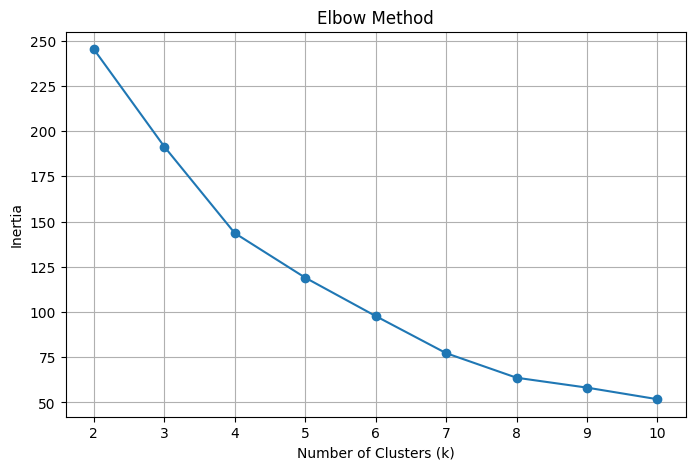

In [220]:
plt.figure(figsize=(8, 5))
plt.plot(K, inertia, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(K)
plt.grid()
plt.show()

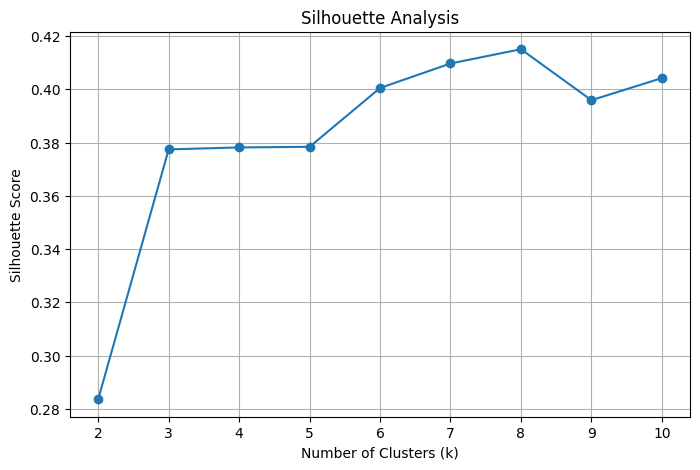

In [221]:
plt.figure(figsize=(8, 5))
plt.plot(K, silhouette_scores, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Analysis")
plt.xticks(K)
plt.grid()
plt.show()

In [222]:
results = pd.DataFrame({
    "k": list(K),
    "inertia": inertia,
    "silhouette_score": silhouette_scores
})

display(results)

,k,inertia,silhouette_score
0,2,245.296999,0.283599
1,3,191.445784,0.377426
2,4,143.613911,0.378164
3,5,118.983825,0.378389
4,6,97.759965,0.400475
5,7,77.241187,0.409686
6,8,63.652775,0.415047
7,9,58.179283,0.395902
8,10,51.767025,0.404196


In [223]:
best_k = int(results.loc[results["silhouette_score"].idxmax(), "k"])
print (best_k)

kmeans_final = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

df_ml["cluster"] = kmeans_final.fit_predict(X_scaled)

display(
    df_ml[["district_en", "cluster"]]
    .sort_values("cluster")
)

8


,district_en,cluster
3,Nong Khaem,0
27,Thung Khru,0
20,Thawi Watthana,0
17,Khlong Sam Wa,0
40,Saphan Sung,0
49,Nong Chok,0
43,Thon Buri,0
15,Watthana,1
10,Bang Khen,1
11,Ratchathewi,1


In [224]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

plot_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "District": df_ml["district_en"].values,
    "Cluster": df_ml["cluster"].values
})

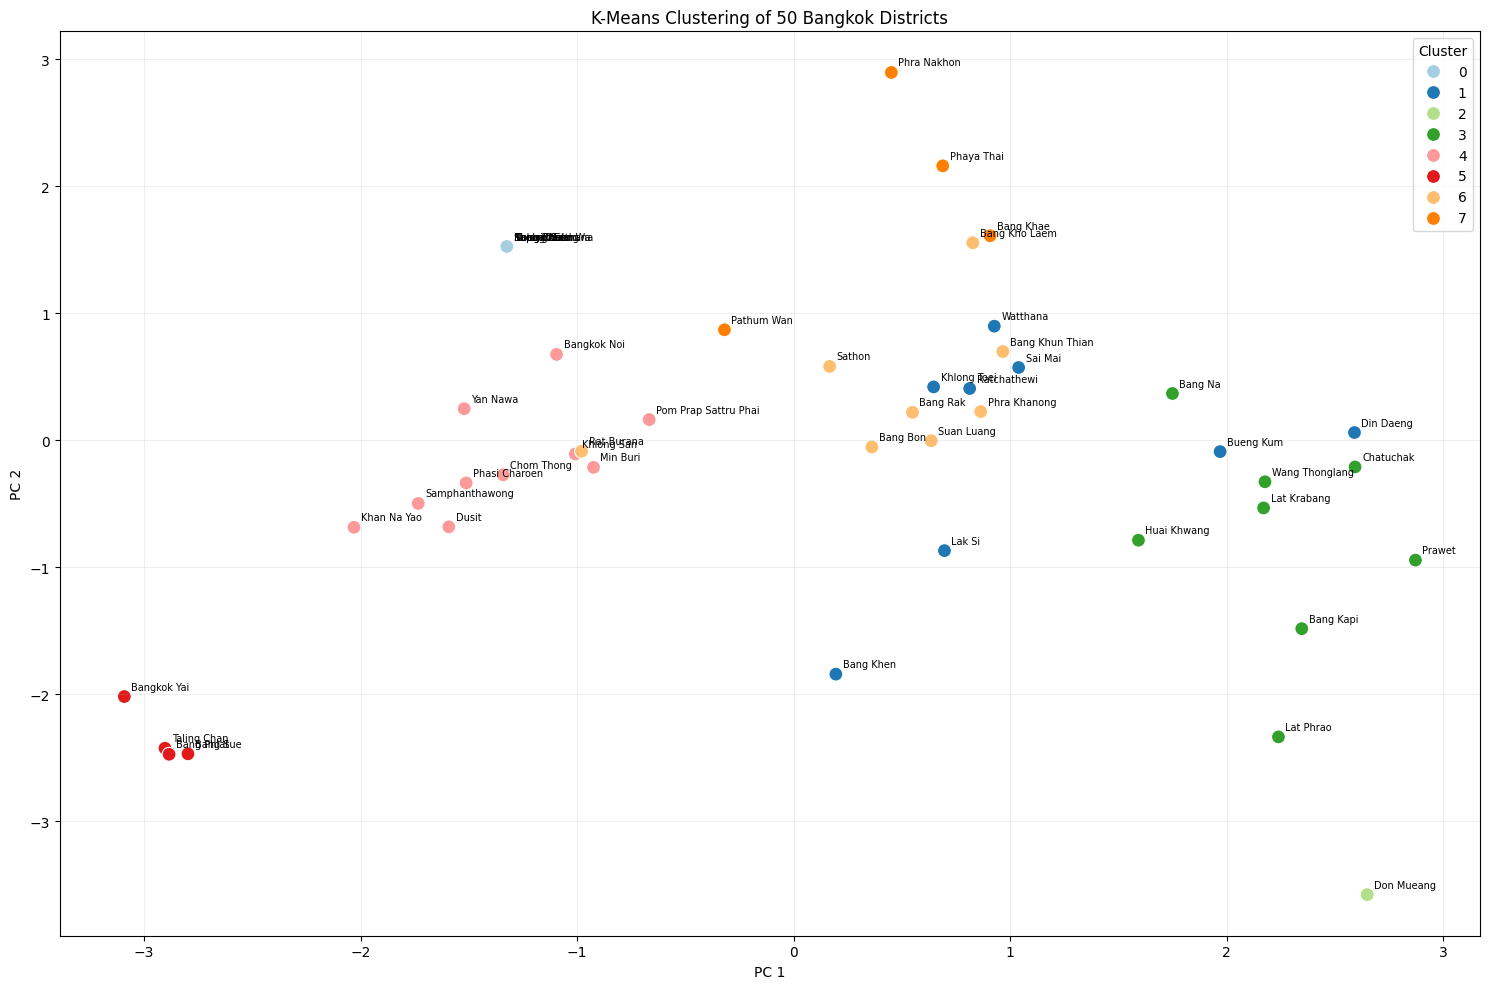

In [225]:
plt.figure(figsize=(15, 10))

sns.scatterplot(
    data=plot_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Paired",
    s=100
)

for _, row in plot_df.iterrows():
    plt.annotate(
        row["District"],
        (row["PC1"], row["PC2"]),
        fontsize=7,
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.title("K-Means Clustering of 50 Bangkok Districts")
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.legend(title="Cluster")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

can't see some districs but it's ok

In [226]:
cluster_sizes = (
    df_ml.groupby("cluster")
    .agg(
        number_of_districts=("district_en", "count"),
        districts=("district_en", lambda x: ", ".join(x))
    )
)

cluster_profile = df_ml.groupby("cluster").agg(
    flood_events=("flood_events", "mean"),
    events_over_3h=("events_over_3h_flood", "mean"),
    avg_rainfall=("avg_rainfall", "mean"),
    avg_min_depth=("avg_min_depth", "mean"),
    avg_max_depth=("avg_max_depth", "mean"),
    avg_duration=("avg_duration", "mean"),
)

display(cluster_sizes)
display(cluster_profile.round(2))

,number_of_districts,districts
cluster,,
0,7,"Nong Khaem, Khlong Sam Wa, Thawi Watthana, Thu..."
1,8,"Lak Si, Khlong Toei, Bueng Kum, Bang Khen, Rat..."
2,1,Don Mueang
3,8,"Chatuchak, Huai Khwang, Lat Krabang, Bang Kapi..."
4,10,"Yan Nawa, Dusit, Min Buri, Khan Na Yao, Bangko..."
5,4,"Taling Chan, Bang Sue, Bangkok Yai, Bang Phlat"
6,8,"Bang Khun Thian, Suan Luang, Phra Khanong, Ban..."
7,4,"Bang Khae, Phra Nakhon, Pathum Wan, Phaya Thai"


,flood_events,events_over_3h,avg_rainfall,avg_min_depth,avg_max_depth,avg_duration
cluster,,,,,,
0,0.00,0.00,67.69,10.00,15.75,95.83
1,41.88,4.50,60.52,10.71,15.85,88.10
2,20.00,13.00,37.58,8.00,12.50,438.00
3,34.75,13.12,71.21,10.29,15.53,199.79
4,4.50,0.20,72.86,8.54,14.15,68.22
5,1.25,0.00,64.12,5.00,10.00,31.88
6,13.38,2.38,58.40,10.82,16.52,124.23
7,12.75,1.25,81.84,12.34,17.89,100.88


**Interpret**

0 = No recorded flood events

1 = Frequent, generally shorter-duration flooding

2 = Distinctive long-duration flooding

3 = Frequent and prolonged flooding

4 = Low recorded flood frequency and shorter duration

5 = Very low recorded flood frequency and short duration

6 = Relatively deep, moderate-duration flooding

7 = High rainfall and relatively deep flooding



### just cheack if k = 8 ok?

In [227]:
for k in [6, 7, 8, 9]:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    print(
        f"k={k} | "
        f"Silhouette={silhouette_score(X_scaled, labels):.3f} | "
        f"Cluster sizes={sorted(pd.Series(labels).value_counts().tolist())}"
    )

k=6 | Silhouette=0.400 | Cluster sizes=[1, 4, 7, 9, 11, 18]
k=7 | Silhouette=0.410 | Cluster sizes=[1, 4, 7, 8, 9, 10, 11]
k=8 | Silhouette=0.415 | Cluster sizes=[1, 4, 4, 7, 8, 8, 8, 10]
k=9 | Silhouette=0.396 | Cluster sizes=[1, 4, 4, 6, 6, 6, 6, 7, 10]


ok!!!

# **Part B: Budget Opt**

In [228]:
import pandas as pd

budget_analysis = df_ml[[
    "district_en",
    "cluster",
    "flood_events",
    "events_over_3h_flood",
    "avg_max_depth",
    "avg_duration",
    "budget_total",
    "budget_embarkment",
    "budget_drainage",
    "budget_dredging",
    "budget_operating",
    "budget_retention",
    "budget_pumps"
]].copy()

budget_analysis["budget_per_event"] = (
    budget_analysis["budget_total"] /
    budget_analysis["flood_events"].replace(0, pd.NA)
)

display(
    budget_analysis.sort_values(
        "budget_total", ascending=False
    ).round(2)
)

,district_en,cluster,flood_events,events_over_3h_flood,avg_max_depth,avg_duration,budget_total,budget_embarkment,budget_drainage,budget_dredging,budget_operating,budget_retention,budget_pumps,budget_per_event
0,Don Mueang,2,20.0,13.0,12.50,438.00,770908200,663106000,67807000,4521000,10674200,20000000,4800000,38545410.0
1,Lak Si,1,52.0,4.0,14.23,82.37,694525825,497197725,63871000,4145000,21512100,99000000,8800000,13356265.865385
2,Khlong Toei,1,36.0,2.0,15.75,82.22,662579448,459377715,170303000,24503333,8395400,0,0,18404984.666667
3,Nong Khaem,0,0.0,0.0,15.75,95.83,658778795,514369262,99955533,23563500,10730500,0,10160000,<NA>
4,Chatuchak,3,49.0,14.0,16.49,130.51,489673667,95000000,341092667,21155500,32425500,0,0,9993340.142857
5,Yan Nawa,4,3.0,0.0,16.67,60.00,383532460,305665960,47995000,21856000,7967500,0,48000,127844153.333333
6,Dusit,4,3.0,0.0,13.33,43.33,352362000,78790000,204300000,2398000,6783000,60000000,91000,117454000.0
7,Bang Khae,7,18.0,3.0,17.50,111.89,336612031,178419818,95003533,43586000,15386680,0,4216000,18700668.388889
8,Bueng Kum,1,45.0,7.0,16.56,107.89,336442484,68600000,165773424,29633000,26340060,45300000,796000,7476499.644444
9,Bang Khun Thian,6,10.0,4.0,17.00,152.70,331725300,106070000,97600000,100769000,26406300,0,880000,33172530.0


In [229]:
cluster_budget = df_ml.groupby("cluster").agg(
    districts=("district_en", "count"),
    avg_flood_events=("flood_events", "mean"),
    avg_events_over_3h=("events_over_3h_flood", "mean"),
    avg_max_depth=("avg_max_depth", "mean"),
    avg_duration=("avg_duration", "mean"),
    avg_budget=("budget_total", "mean"),
    total_budget=("budget_total", "sum")
)

display(cluster_budget.round(2))

,districts,avg_flood_events,avg_events_over_3h,avg_max_depth,avg_duration,avg_budget,total_budget
cluster,,,,,,,
0,7,0.00,0.00,15.75,95.83,2.129827e+08,1490878728
1,8,41.88,4.50,15.85,88.10,3.463007e+08,2770405596
2,1,20.00,13.00,12.50,438.00,7.709082e+08,770908200
3,8,34.75,13.12,15.53,199.79,2.356286e+08,1885028513
4,10,4.50,0.20,14.15,68.22,1.975365e+08,1975365178
5,4,1.25,0.00,10.00,31.88,1.521547e+08,608618619
6,8,13.38,2.38,16.52,124.23,1.295372e+08,1036297278
7,4,12.75,1.25,17.89,100.88,1.951360e+08,780544063


**cluster 1** max avg flood event but high budget

**cluster 3** top 2 most event bu lower budget that **cluster 1**

**cluster 6** everything is higher than a cluster 7 but lower budget

## **flood priority score**

In [232]:
priority_df = df_ml[[
    "district_en",
    "cluster",
    "flood_events",
    "events_over_3h_flood",
    "avg_max_depth",
    "avg_duration",
    "budget_total"
]].copy()

observed = priority_df["flood_events"] > 0

priority_features = [
    "flood_events",
    "events_over_3h_flood",
    "avg_max_depth",
    "avg_duration"
]

scaler_priority = MinMaxScaler()

priority_df.loc[observed, priority_features] = (
    scaler_priority.fit_transform(
        priority_df.loc[observed, priority_features]
    )
)

weights = {
    "flood_events": 0.25,
    "events_over_3h_flood": 0.25,
    "avg_max_depth": 0.25,
    "avg_duration": 0.25
}

priority_df["priority_score"] = np.nan

priority_df.loc[observed, "priority_score"] = (
    sum(
        priority_df.loc[observed, feature] * weight
        for feature, weight in weights.items()
    ) * 100
)

priority_df["priority_rank"] = (
    priority_df["priority_score"]
    .rank(ascending=False, method="min")
)

display(
    priority_df.sort_values(
        "priority_score", ascending=False
    ).round(2)
)

,district_en,cluster,flood_events,events_over_3h_flood,avg_max_depth,avg_duration,budget_total,priority_score,priority_rank
4,Chatuchak,3,0.86,0.82,0.65,0.26,489673667,64.63,1.0
25,Prawet,3,0.57,0.88,0.59,0.54,188822733,64.62,2.0
22,Bang Kapi,3,0.77,0.94,0.44,0.40,204014324,63.68,3.0
38,Din Daeng,1,1.00,0.59,0.72,0.19,87160616,62.44,4.0
35,Lat Phrao,3,0.54,1.00,0.37,0.56,111540491,61.63,5.0
23,Wang Thonglang,3,0.55,0.76,0.61,0.43,192879124,59.02,6.0
0,Don Mueang,2,0.34,0.76,0.25,1.00,770908200,58.85,7.0
18,Lat Krabang,3,0.61,0.59,0.60,0.39,266246800,54.65,8.0
16,Huai Khwang,3,0.48,0.71,0.50,0.38,275192774,51.75,9.0
8,Bueng Kum,1,0.79,0.41,0.66,0.20,336442484,51.34,10.0


### **compare flood prior**

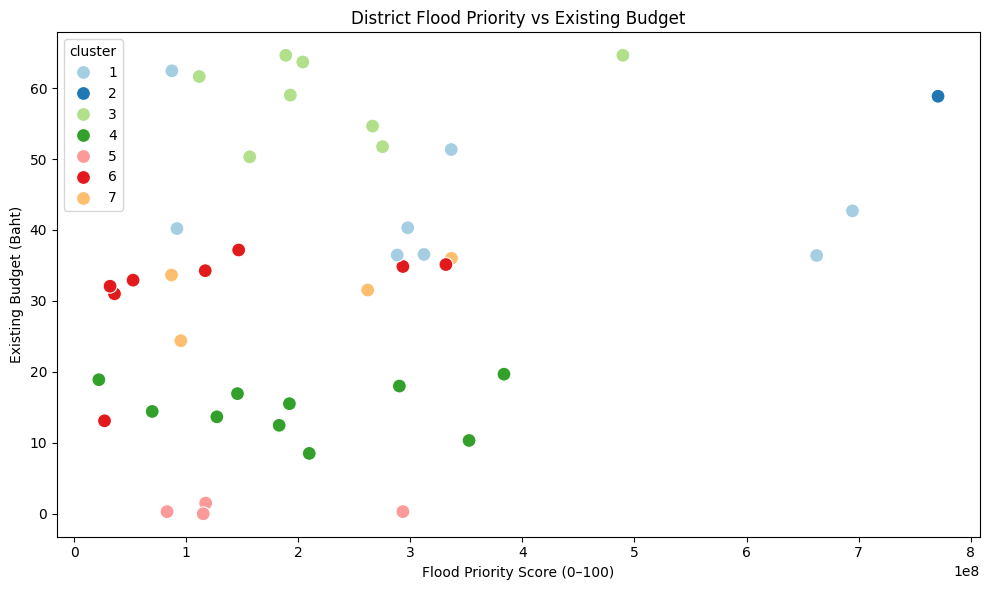

In [261]:
import matplotlib.pyplot as plt
import seaborn as sns

plot_data = priority_df.dropna(
    subset=["priority_score"]
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=plot_data,
    y="priority_score",
    x="budget_total",
    hue="cluster",
    palette="Paired",
    s=100
)

plt.xlabel("Flood Priority Score (0–100)")
plt.ylabel("Existing Budget (Baht)")
plt.title("District Flood Priority vs Existing Budget")

plt.ticklabel_format(
    style="plain", axis="y"
)

plt.tight_layout()
plt.show()

I mean, Top 10 ranked districs are mostly cluster 3

And that make me think that "whether my weight scoring method bad?" beacuse, maybe, the flood duration and frequency are correlation to each other. But it's ok we can test it later.

## **making scenario**
and compare models

### **Allocation model**
90% for the distric cal by the prior

10% for the cluster 7 (equally)

In [236]:
allocation_df = priority_df.copy()

TOTAL_BUDGET = allocation_df["budget_total"].sum()

observed_mask = allocation_df["priority_score"].notna()
no_record_mask = ~observed_mask

priority_budget_share = 0.90
reserve_share = 0.10

priority_budget = TOTAL_BUDGET * priority_budget_share
reserve_budget = TOTAL_BUDGET * reserve_share

allocation_df["proposed_budget"] = 0.0

allocation_df.loc[observed_mask, "proposed_budget"] = (
    allocation_df.loc[observed_mask, "priority_score"]
    / allocation_df.loc[observed_mask, "priority_score"].sum()
    * priority_budget
)

allocation_df.loc[no_record_mask, "proposed_budget"] = (
    reserve_budget / no_record_mask.sum()
)

allocation_df["budget_difference"] = (
    allocation_df["proposed_budget"]
    - allocation_df["budget_total"]
)

allocation_df["budget_change_percent"] = (
    allocation_df["budget_difference"]
    / allocation_df["budget_total"] * 100
)

display(
    allocation_df[[
        "district_en",
        "cluster",
        "priority_score",
        "budget_total",
        "proposed_budget",
        "budget_difference",
        "budget_change_percent"
    ]].sort_values("priority_score", ascending=False).round(2)
)

print("Existing total:", TOTAL_BUDGET)
print("Proposed total:", allocation_df["proposed_budget"].sum())
print("budget_change_percent:", allocation_df["budget_change_percent"].sort_values())

,district_en,cluster,priority_score,budget_total,proposed_budget,budget_difference,budget_change_percent
4,Chatuchak,3,64.63,489673667,4.694624e+08,-2.021126e+07,-4.13
25,Prawet,3,64.62,188822733,4.694244e+08,2.806016e+08,148.61
22,Bang Kapi,3,63.68,204014324,4.625787e+08,2.585643e+08,126.74
38,Din Daeng,1,62.44,87160616,4.535342e+08,3.663736e+08,420.34
35,Lat Phrao,3,61.63,111540491,4.476730e+08,3.361325e+08,301.35
23,Wang Thonglang,3,59.02,192879124,4.286907e+08,2.358115e+08,122.26
0,Don Mueang,2,58.85,770908200,4.274883e+08,-3.434199e+08,-44.55
18,Lat Krabang,3,54.65,266246800,3.969692e+08,1.307224e+08,49.10
16,Huai Khwang,3,51.75,275192774,3.758812e+08,1.006884e+08,36.59
8,Bueng Kum,1,51.34,336442484,3.729611e+08,3.651863e+07,10.85


Existing total: 11318046175
Proposed total: 11318046175.0
budget_change_percent: 34   -100.000000
13    -99.250480
41    -97.346286
32    -90.676321
6     -78.692085
3     -75.456652
21    -70.519100
5     -62.729786
2     -60.088108
1     -55.340393
14    -54.933418
26    -50.463684
0     -44.547440
24    -41.298590
17    -40.321871
20    -25.978092
9     -23.072469
7     -22.289287
31    -22.023842
30    -15.560777
10    -14.919391
12    -13.678973
19    -12.547356
27    -11.494057
15     -8.072945
4      -4.127496
11     -1.617345
8      10.854346
16     36.588315
18     49.098205
42     50.560970
29     84.019009
36     86.210170
40     88.609867
33    112.873996
23    122.258719
22    126.738325
28    133.289290
25    148.605852
39    181.588850
43    192.682103
37    218.457586
47    251.783397
35    301.354683
44    355.373926
38    420.343080
48    524.110725
45    526.523001
46    628.532038
49    747.133147
Name: budget_change_percent, dtype: float64


### **improve the allocation model**

I think the earlier can be dev (and the margin is so high, i will use this following method

* Preserve 90% of each district's existing budget.
* Redistribute the remaining 10% according to flood priority.
* Keep the 10% reserve for districts without recorded flood events.
* Maintain the same total budget.

In [237]:
allocation_v2 = priority_df.copy()

TOTAL_BUDGET = allocation_v2["budget_total"].sum()

observed_mask = allocation_v2["priority_score"].notna()
no_record_mask = ~observed_mask

protected_share = 0.90
redistribution_share = 0.10

allocation_v2["proposed_budget"] = (
    allocation_v2["budget_total"] * protected_share
)

redistribution_budget = TOTAL_BUDGET * redistribution_share

priority_pool = redistribution_budget * 0.90
reserve_pool = redistribution_budget * 0.10

allocation_v2.loc[observed_mask, "proposed_budget"] += (
    allocation_v2.loc[observed_mask, "priority_score"]
    / allocation_v2.loc[observed_mask, "priority_score"].sum()
    * priority_pool
)

allocation_v2.loc[no_record_mask, "proposed_budget"] += (
    reserve_pool / no_record_mask.sum()
)

allocation_v2["budget_difference"] = (
    allocation_v2["proposed_budget"]
    - allocation_v2["budget_total"]
)

allocation_v2["budget_change_percent"] = (
    allocation_v2["budget_difference"]
    / allocation_v2["budget_total"] * 100
)

display(
    allocation_v2[[
        "district_en",
        "cluster",
        "priority_score",
        "budget_total",
        "proposed_budget",
        "budget_difference",
        "budget_change_percent"
    ]].sort_values(
        "priority_score", ascending=False
    ).round(2)
)

print("Existing total:", TOTAL_BUDGET)
print("Proposed total:", allocation_v2["proposed_budget"].sum())

,district_en,cluster,priority_score,budget_total,proposed_budget,budget_difference,budget_change_percent
4,Chatuchak,3,64.63,489673667,4.876525e+08,-2021126.16,-0.41
25,Prawet,3,64.62,188822733,2.168829e+08,28060163.11,14.86
22,Bang Kapi,3,63.68,204014324,2.298708e+08,25856433.68,12.67
38,Din Daeng,1,62.44,87160616,1.237980e+08,36637361.79,42.03
35,Lat Phrao,3,61.63,111540491,1.451537e+08,33613249.33,30.14
23,Wang Thonglang,3,59.02,192879124,2.164603e+08,23581154.53,12.23
0,Don Mueang,2,58.85,770908200,7.365662e+08,-34341987.09,-4.45
18,Lat Krabang,3,54.65,266246800,2.793190e+08,13072239.87,4.91
16,Huai Khwang,3,51.75,275192774,2.852616e+08,10068839.90,3.66
8,Bueng Kum,1,51.34,336442484,3.400943e+08,3651863.14,1.09


Existing total: 11318046175
Proposed total: 11318046175.0


### **Compare**



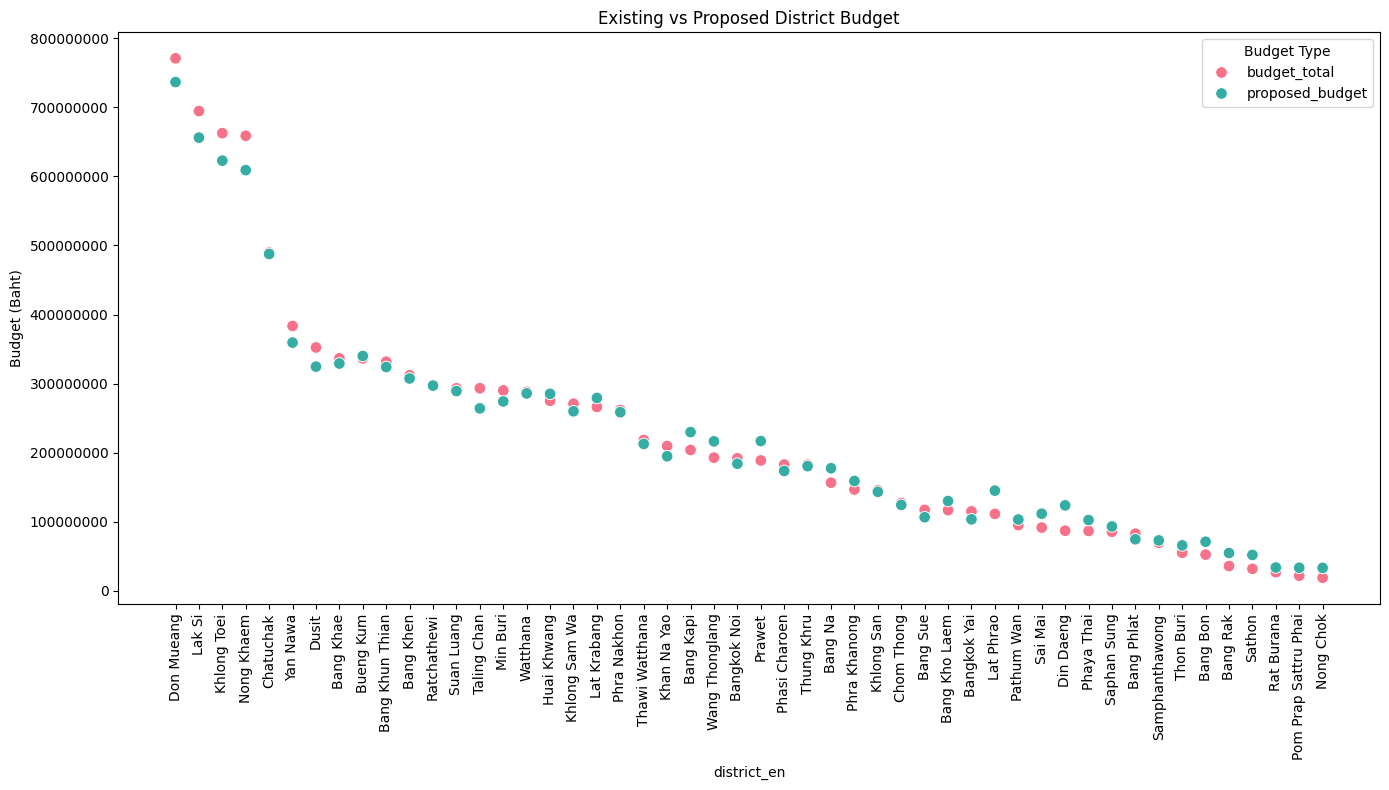

In [250]:
import matplotlib.pyplot as plt
import seaborn as sns

comparison = allocation_v2.melt(
    id_vars="district_en",
    value_vars=["budget_total", "proposed_budget"],
    var_name="Budget Type",
    value_name="Budget"
)

plt.figure(figsize=(14, 8))

sns.scatterplot(
    data=comparison,
    x="district_en",
    y="Budget",
    hue="Budget Type",
    s=70,
    palette = "husl"
)

plt.xticks(rotation=90)
plt.ylabel("Budget (Baht)")
plt.title("Existing vs Proposed District Budget")
plt.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()

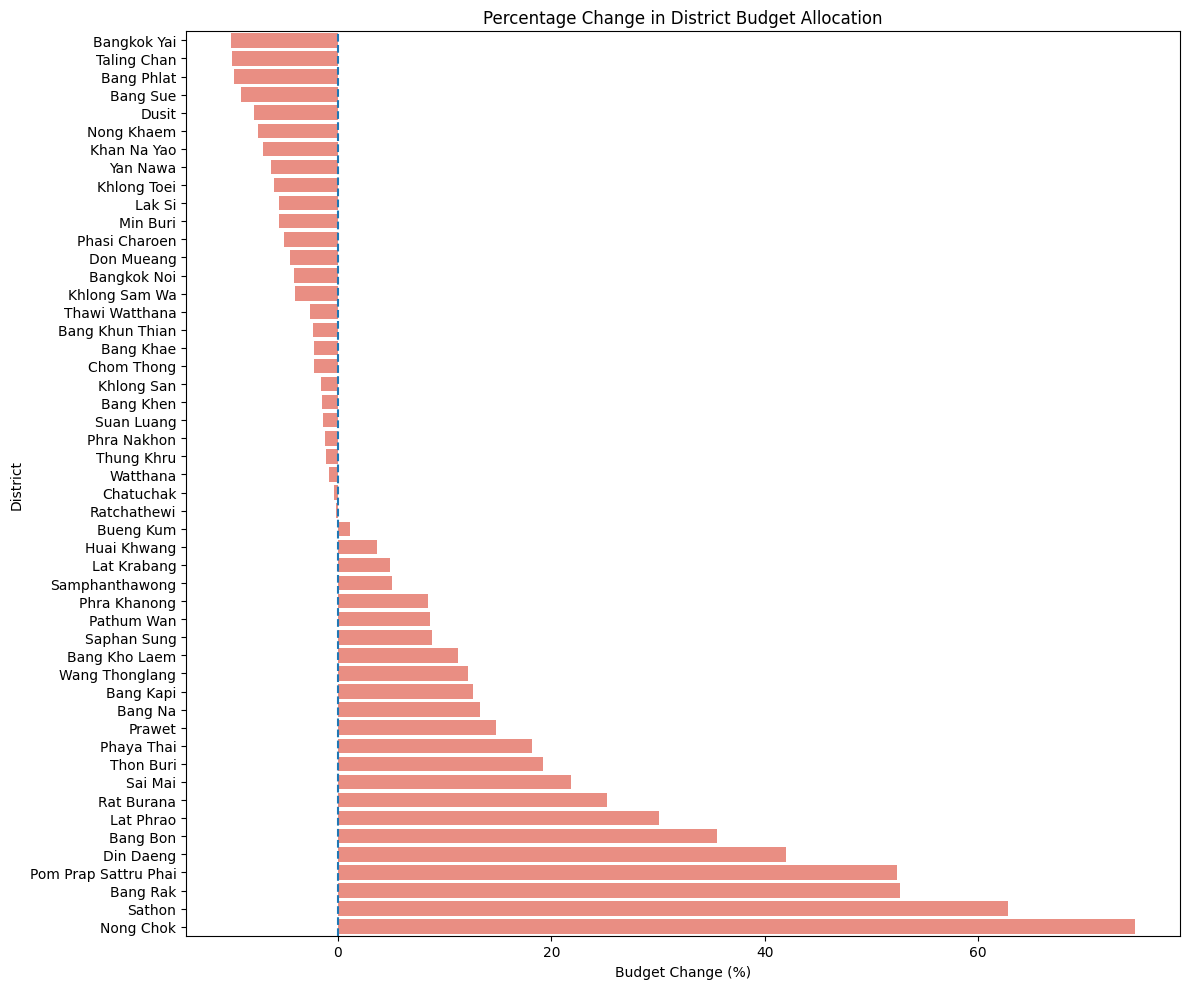

In [247]:
change_df = allocation_v2.sort_values(
    "budget_change_percent"
)

plt.figure(figsize=(12, 10))

sns.barplot(
    data=change_df,
    x="budget_change_percent",
    y="district_en",
    color = "salmon"
)

plt.axvline(0, linestyle="--")
plt.xlabel("Budget Change (%)")
plt.ylabel("District")
plt.title("Percentage Change in District Budget Allocation")
plt.tight_layout()
plt.show()

In [252]:
comparison = allocation_v2[[
    "district_en",
    "cluster",
    "priority_score",
    "priority_rank",
    "budget_total",
    "proposed_budget",
    "budget_difference",
    "budget_change_percent"
]].copy()

comparison = comparison.sort_values(
    "budget_change_percent",
    ascending=False
)

comparison.head(10)

,district_en,cluster,priority_score,priority_rank,budget_total,proposed_budget,budget_difference,budget_change_percent
49,Nong Chok,0,NaN,NaN,19086300,3.334631e+07,1.426001e+07,74.713315
46,Sathon,6,32.078017,25.0,31984400,5.208762e+07,2.010322e+07,62.853204
45,Bang Rak,6,31.008670,27.0,35952200,5.488186e+07,1.892966e+07,52.652300
48,Pom Prap Sattru Phai,4,18.898958,30.0,21996600,3.352525e+07,1.152865e+07,52.411072
38,Din Daeng,1,62.435376,4.0,87160616,1.237980e+08,3.663736e+07,42.034308
44,Bang Bon,6,32.932898,24.0,52534080,7.120332e+07,1.866924e+07,35.537393
35,Lat Phrao,3,61.628492,5.0,111540491,1.451537e+08,3.361325e+07,30.135468
47,Rat Burana,6,13.105327,36.0,27061500,3.387514e+07,6.813636e+06,25.178340
37,Sai Mai,1,40.205954,14.0,91710300,1.117451e+08,2.003481e+07,21.845759
43,Thon Buri,0,NaN,NaN,55243000,6.588734e+07,1.064434e+07,19.268210


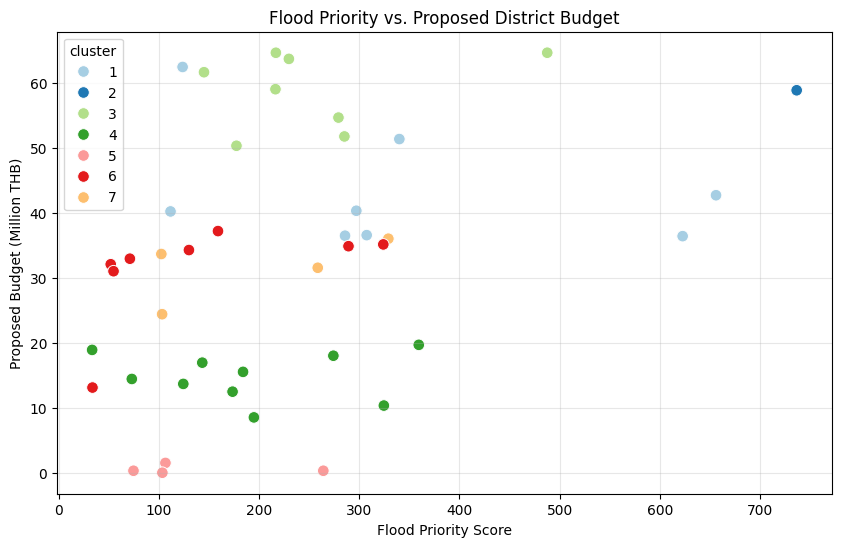

In [259]:
import matplotlib.pyplot as plt
import seaborn as sns

plot_df = comparison.dropna(subset=["priority_score"])

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=plot_df,
    y="priority_score",
    x=plot_df["proposed_budget"] / 1e6,
    hue="cluster",
    palette="Paired",
    s=70
)

plt.xlabel("Flood Priority Score")
plt.ylabel("Proposed Budget (Million THB)")
plt.title("Flood Priority vs. Proposed District Budget")
plt.grid(alpha=0.3)

plt.show()

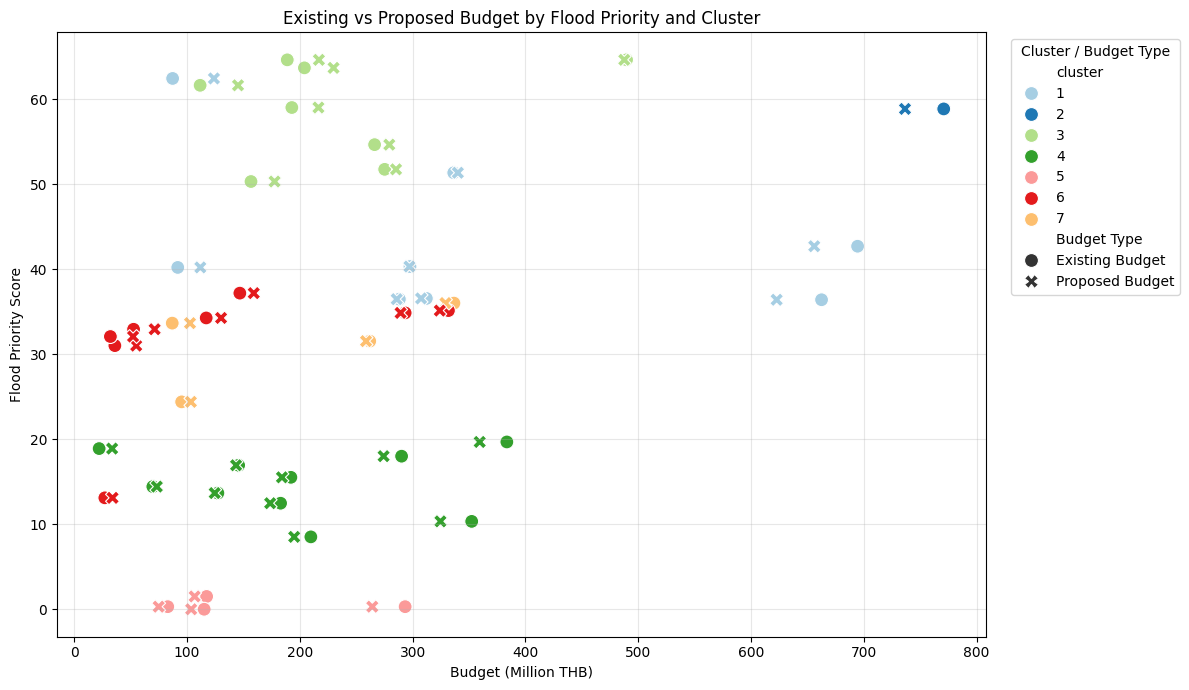

In [257]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Combine existing and proposed budget data
plot_df = allocation_v2[[
    "district_en",
    "cluster",
    "priority_score",
    "budget_total",
    "proposed_budget"
]].copy()

# Convert budgets to million THB
plot_df["Existing Budget"] = plot_df["budget_total"] / 1e6
plot_df["Proposed Budget"] = plot_df["proposed_budget"] / 1e6

# Convert to long format for plotting
plot_long = plot_df.melt(
    id_vars=["district_en", "cluster", "priority_score"],
    value_vars=["Existing Budget", "Proposed Budget"],
    var_name="Budget Type",
    value_name="Budget (Million THB)"
)

# Exclude districts without recorded flood events
plot_long = plot_long.dropna(subset=["priority_score"])

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=plot_long,
    x="Budget (Million THB)",
    y="priority_score",
    hue="cluster",
    style="Budget Type",
    s=100,
    palette="Paired"
)

plt.title("Existing vs Proposed Budget by Flood Priority and Cluster")
plt.xlabel("Budget (Million THB)")
plt.ylabel("Flood Priority Score")
plt.grid(alpha=0.3)
plt.legend(title="Cluster / Budget Type", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

Notice that budgets of the high risk-scored cluster are **increasing**

while

the low risk-scored cluster's budgets are **decreasing**.

# **Recommendations**

> Where should Bangkok investigate funding needs more closely?




In [269]:
merged_temp = allocation_v2.merge(df_ml[["district_en", "district"]], on="district_en", how="left")

merged_temp.loc[(merged_temp["priority_score"] > 50) & (merged_temp["proposed_budget"] < 2e8), ["district", "district_en", "cluster", "proposed_budget"]]

,district,district_en,cluster,proposed_budget
28,บางนา,Bang Na,3,1.775395e+08
35,ลาดพร้าว,Lat Phrao,3,1.451537e+08
38,ดินแดง,Din Daeng,1,1.237980e+08


beacuse high risk-score but low budget (because the proposed budget is based on existing budget)

> What are the model's limitations?

Our data does not show how much flood damage each baht of investment can prevent, so we cannot claim that the proposed allocation is the mathematically optimal way to reduce flood damage.